In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('teacher_activity_logs.csv')

print("Размер таблицы:", df.shape)
print("\nНазвания колонок:")
print(df.columns.tolist())

print("\nПервые 5 строк:")
display(df.head())

print("\nИнформация о типах данных и пропусках:")
print(df.info())

Размер таблицы: (214959, 7)

Названия колонок:
['user_id', 'timestamp', 'event_type', 'module', 'session_id', 'region', 'school_id']

Первые 5 строк:


,user_id,timestamp,event_type,module,session_id,region,school_id
0,BOT001,2026-03-01 00:00:48,webinar_hosted,Вебинары,SBOT,Москва,1
1,BOT004,2026-03-01 00:01:44,webinar_started,Вебинары,SBOT,Москва,1
2,BOT014,2026-03-01 00:02:41,material_downloaded,Библиотека материалов,SBOT,Москва,1
3,BOT001,2026-03-01 00:03:38,webinar_hosted,Вебинары,SBOT,Москва,1
4,BOT002,2026-03-01 00:04:31,homework_assigned,Домашние задания,SBOT,Москва,1



Информация о типах данных и пропусках:
<class 'pandas.DataFrame'>
RangeIndex: 214959 entries, 0 to 214958
Data columns (total 7 columns):
 #   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   user_id     214959 non-null  str  
 1   timestamp   214959 non-null  str  
 2   event_type  214959 non-null  str  
 3   module      202153 non-null  str  
 4   session_id  214959 non-null  str  
 5   region      214959 non-null  str  
 6   school_id   214959 non-null  int64
dtypes: int64(1), str(6)
memory usage: 11.5 MB
None


In [2]:
# сколько ботов и удаляем
bots = df[df['user_id'].str.startswith('BOT')]
print(f"Количество строк с ботами: {len(bots)}")
print(f"Уникальных ботов: {bots['user_id'].nunique()}")

df_clean = df[~df['user_id'].str.startswith('BOT')].copy()
print(f"Размер после удаления ботов: {len(df_clean)} строк")


df_clean['module'] = df_clean['module'].fillna('Unknown')
print(f"Пропусков в module после заполнения: {df_clean['module'].isna().sum()}")

df_clean['timestamp'] = pd.to_datetime(df_clean['timestamp'])

print("\nУникальные события на платформе:")
print(df_clean['event_type'].value_counts())

# проверка на дубликаты
duplicates = df_clean.duplicated(subset=['user_id', 'timestamp', 'event_type']).sum()
print(f"\nНайдено дубликатов: {duplicates}")
df_clean = df_clean.drop_duplicates(subset=['user_id', 'timestamp', 'event_type'])
print(f"Размер после удаления дубликатов: {len(df_clean)} строк")

Количество строк с ботами: 94291
Уникальных ботов: 15
Размер после удаления ботов: 120668 строк
Пропусков в module после заполнения: 0

Уникальные события на платформе:
event_type
homework_assigned      24996
homework_checked       24950
material_downloaded    12899
material_viewed        12894
grade_viewed           11841
grade_entered          11661
schedule_viewed        10158
webinar_started         5690
webinar_hosted          5579
Name: count, dtype: int64

Найдено дубликатов: 71
Размер после удаления дубликатов: 120597 строк


In [4]:
# все активности
total_events = df_clean.groupby('user_id').size().reset_index(name='total_events')

# регулярность
df_clean['date'] = df_clean['timestamp'].dt.date
active_days = df_clean.groupby('user_id')['date'].nunique().reset_index(name='active_days')

pivot_events = pd.crosstab(df_clean['user_id'], df_clean['event_type'])

pivot_modules = pd.crosstab(df_clean['user_id'], df_clean['module'])

features = total_events.merge(active_days, on='user_id').merge(pivot_events, on='user_id').merge(pivot_modules, on='user_id')

print(f"Размер матрицы признаков: {features.shape} (пользователей: {features.shape[0]})")
print("\nСписок сгенерированных признаков:")
print(features.columns.tolist())

display(features.head())

features.to_csv('teacher_features.csv', index=False)

Размер матрицы признаков: (1500, 18) (пользователей: 1500)

Список сгенерированных признаков:
['user_id', 'total_events', 'active_days', 'grade_entered', 'grade_viewed', 'homework_assigned', 'homework_checked', 'material_downloaded', 'material_viewed', 'schedule_viewed', 'webinar_hosted', 'webinar_started', 'Unknown', 'Библиотека материалов', 'Вебинары', 'Домашние задания', 'Оценки', 'Расписание']


,user_id,total_events,active_days,grade_entered,grade_viewed,homework_assigned,homework_checked,material_downloaded,material_viewed,schedule_viewed,webinar_hosted,webinar_started,Unknown,Библиотека материалов,Вебинары,Домашние задания,Оценки,Расписание
0,T100000,38,11,0,3,3,0,2,1,9,11,9,2,2,19,3,3,9
1,T100001,40,18,1,1,2,3,12,15,4,1,1,2,25,2,5,2,4
2,T100002,16,8,1,1,1,1,3,2,5,2,0,1,4,2,2,2,5
3,T100003,33,9,1,2,1,1,2,0,4,13,9,1,2,21,2,3,4
4,T100004,155,31,14,19,43,50,5,8,5,10,1,13,13,9,87,30,3


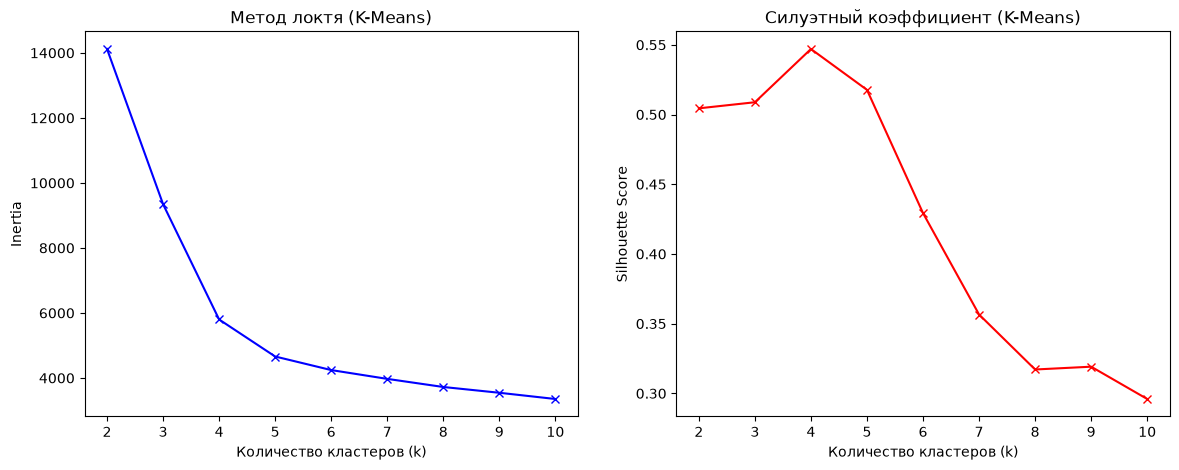

Количество кластеров K-Means: 4
Количество кластеров DBSCAN (включая шум -1): 4

Распределение по кластерам K-Means:
kmeans_cluster
2    507
0    449
1    337
3    207
Name: count, dtype: int64


In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

X = features.drop(columns=['user_id']).copy()

# стандартизация
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# поиск оптимального числа кластеров для K-Means
inertia = []
silhouette = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)
    silhouette.append(silhouette_score(X_scaled, kmeans.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(K_range, inertia, 'bx-')
ax1.set_xlabel('Количество кластеров (k)')
ax1.set_ylabel('Inertia')
ax1.set_title('Метод локтя (K-Means)')

ax2.plot(K_range, silhouette, 'rx-')
ax2.set_xlabel('Количество кластеров (k)')
ax2.set_ylabel('Silhouette Score')
ax2.set_title('Силуэтный коэффициент (K-Means)')
plt.show()

# запуск K-Means 
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
features['kmeans_cluster'] = kmeans.fit_predict(X_scaled)

# запуск DBSCAN
dbscan = DBSCAN(eps=1.5, min_samples=10)
features['dbscan_cluster'] = dbscan.fit_predict(X_scaled)

print(f"Количество кластеров K-Means: {features['kmeans_cluster'].nunique()}")
print(f"Количество кластеров DBSCAN (включая шум -1): {features['dbscan_cluster'].nunique()}")
print("\nРаспределение по кластерам K-Means:")
print(features['kmeans_cluster'].value_counts())

Профиль кластеров (ср.знач.):


,total_events,active_days,grade_entered,grade_viewed,homework_assigned,homework_checked,material_downloaded,material_viewed,schedule_viewed,webinar_hosted,webinar_started,Unknown,Библиотека материалов,Вебинары,Домашние задания,Оценки,Расписание,kmeans_cluster,dbscan_cluster,users_count
kmeans_cluster,,,,,,,,,,,,,,,,,,,,
0,184.9,33.7,22.7,23.0,50.8,50.8,9.3,9.4,9.5,4.5,4.8,10.9,17.7,8.8,95.6,43.1,8.9,0.0,1.3,449
1,14.4,7.0,1.2,1.3,1.3,1.4,2.3,2.3,2.9,0.9,0.9,0.9,4.3,1.7,2.5,2.4,2.7,1.0,1.0,337
2,45.3,18.1,1.1,1.1,2.4,2.3,14.7,14.7,6.7,1.1,1.1,2.6,27.7,2.1,4.5,2.1,6.3,2.0,1.0,507
3,47.1,11.7,2.4,2.3,2.4,2.3,2.3,2.2,7.4,12.9,12.9,2.8,4.3,24.2,4.4,4.3,7.0,3.0,-0.0,207


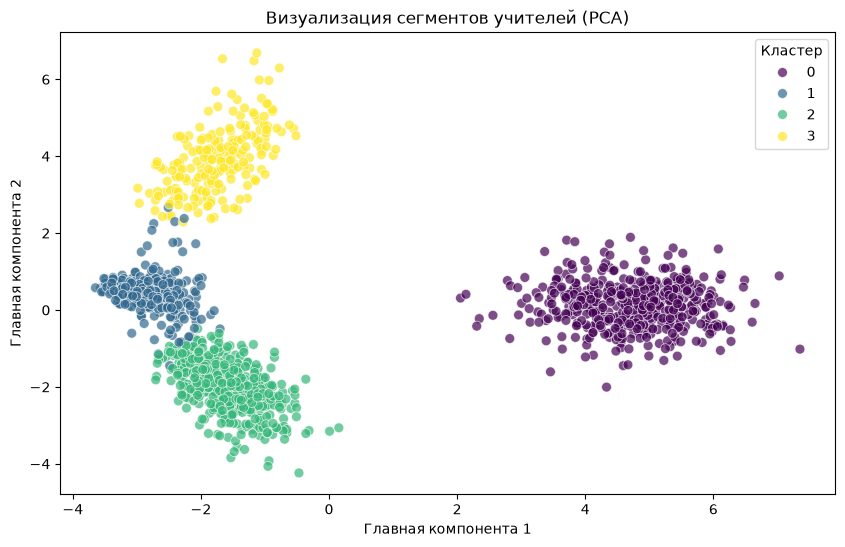

In [8]:
# средние значения признаков для каждого кластера
cluster_profile = features.groupby('kmeans_cluster')[X.columns].mean().round(1)

cluster_profile['users_count'] = features['kmeans_cluster'].value_counts()

print("Профиль кластеров (ср.знач.):")
display(cluster_profile)

# визуализация
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=features['kmeans_cluster'], palette='viridis', s=50, alpha=0.7)
plt.title('Визуализация сегментов учителей (PCA)')
plt.xlabel('Главная компонента 1')
plt.ylabel('Главная компонента 2')
plt.legend(title='Кластер')
plt.show()

=== Сравнение алгоритмов ===
K-Means (k=4): 4 кластеров
DBSCAN: 3 кластеров + шум
Шумовых точек в DBSCAN: 117


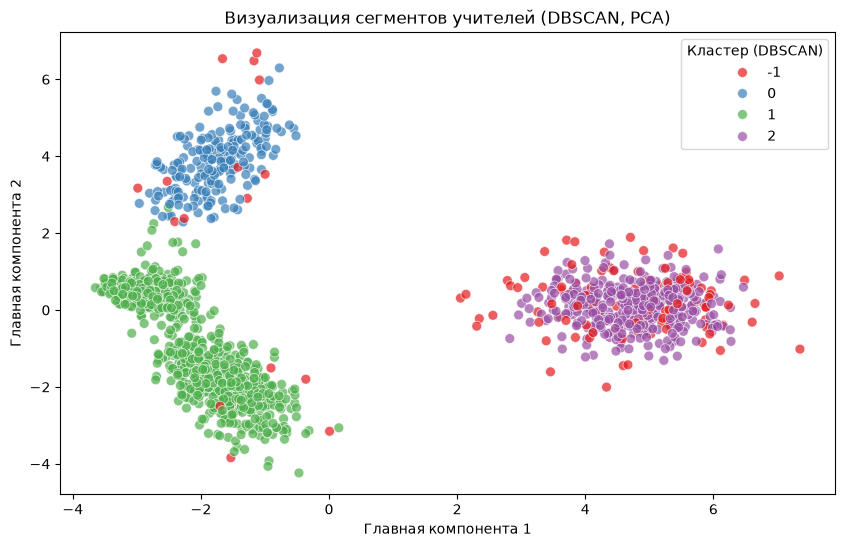

In [9]:
# сравнение K-Means и DBSCAN
print("=== Сравнение алгоритмов ===")
print(f"K-Means (k=4): {features['kmeans_cluster'].nunique()} кластеров")
print(f"DBSCAN: {features['dbscan_cluster'].nunique() - (1 if -1 in features['dbscan_cluster'].values else 0)} кластеров + шум")
print(f"Шумовых точек в DBSCAN: {(features['dbscan_cluster'] == -1).sum()}")

# визуализация DBSCAN для сравнения
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=features['dbscan_cluster'], palette='Set1', s=50, alpha=0.7)
plt.title('Визуализация сегментов учителей (DBSCAN, PCA)')
plt.xlabel('Главная компонента 1')
plt.ylabel('Главная компонента 2')
plt.legend(title='Кластер (DBSCAN)')
plt.show()


=== Оценка классификатора ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        98
           1       1.00      0.97      0.99        72
           2       0.98      1.00      0.99        92
           3       1.00      1.00      1.00        38

    accuracy                           0.99       300
   macro avg       0.99      0.99      0.99       300
weighted avg       0.99      0.99      0.99       300



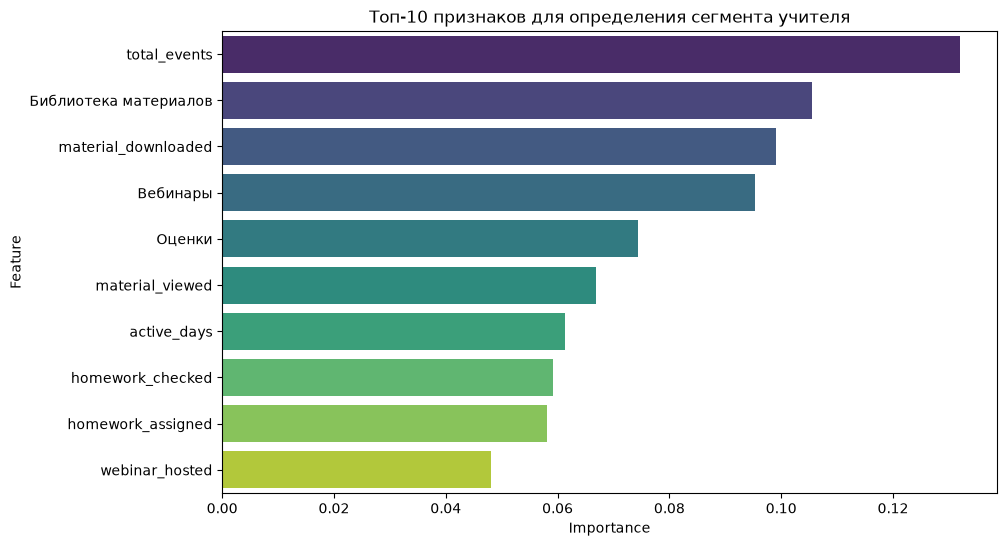

Модель и скалер сохранены!


In [12]:
# алгоритм классификации
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import joblib

cols_to_drop = ['user_id', 'kmeans_cluster', 'dbscan_cluster']
X_clean = features.drop(columns=[c for c in cols_to_drop if c in features.columns])
y = features['kmeans_cluster']

scaler = StandardScaler()
X_scaled_clean = scaler.fit_transform(X_clean)

# обучение Random Forest
X_train, X_test, y_train, y_test = train_test_split(X_scaled_clean, y, test_size=0.2, random_state=42)
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
print("=== Оценка классификатора ===")
print(classification_report(y_test, y_pred))

# важные признаки для определения сегмента
importances = clf.feature_importances_
feature_names = X_clean.columns  # <--- ВОТ ТУТ ИСПРАВЛЕНИЕ
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df.head(10), palette='viridis', hue='Feature', legend=False)
plt.title('Топ-10 признаков для определения сегмента учителя')
plt.show()

joblib.dump(clf, 'teacher_segment_classifier.pkl')
joblib.dump(scaler, 'teacher_scaler.pkl')
print("Модель и скалер сохранены!")

In [13]:
# дашборд
cluster_names = {
    0: 'Учителя-трудяги',
    1: 'Спящие/Новички',
    2: 'Библиотекари',
    3: 'Вебинарщики'
}
features['segment_name'] = features['kmeans_cluster'].map(cluster_names)

features_for_dashboard = features.drop(columns=['dbscan_cluster'], errors='ignore')
features_for_dashboard.to_csv('teacher_segments_final.csv', index=False)
print("Файл 'teacher_segments_final.csv' сохранен! Можно загружать в DataLens.")

Файл 'teacher_segments_final.csv' сохранен! Можно загружать в DataLens.


# Сегментация пользователей EdTech-платформы

## 1. Бизнес-резюме
*   **Проблема:** Единые рассылки и интерфейс не учитывают различия в поведении учителей, что снижает вовлеченность (MAU) и приводит к отпискам.
*   **Решение:** Проведена кластеризация 1500 учителей на основе логов активности (120 597 записей). Выделено 4 поведенческих сегмента. Обучена ML-модель (Random Forest, точность 99%) для автоматического отнесения новых учителей к сегментам.
*   **Бизнес-эффект:** Персонализация коммуникаций и интерфейса под каждый сегмент позволит повысить Retention и активность на платформе.

---

## 2. Предобработка данных 
В ходе EDA были выявлены и устранены аномалии:
*   **Очистка от ботов:** Удалены 15 тестовых аккаунтов (с префиксом `BOT`), которые генерировали 94 291 запись (почти 50% датасета). Итоговый размер выборки: 120 597 событий.
*   **Обработка пропусков:** Заполнены пропуски в модуле (`module` -> `Unknown`).
*   **Дубликаты:** Удален 71 дубликат событий.
*   **Результат:** Чистый датасет из 1500 реальных учителей, готовый к моделированию.

---

## 3. Выбор оптимального числа кластеров
Для выбора оптимального числа кластеров (k) были построены графики метода локтя и силуэтного коэффициента. Пик силуэта и изгиб на графике локтя указывают на k=4.

![локоть и силуэт](elbow_silhouette.png)

---

## 4. Результаты кластеризации
Алгоритм K-Means разделил учителей на 4 сегмента. На графике ниже (проекция PCA) видно четкое разделение групп.

![пса](pca_clusters.png)

### Профили сегментов:

1.  **«Учителя-трудяги» (449 чел.):** Ядро платформы. Максимальная активность, чаще всех задают и проверяют ДЗ, выставляют оценки.
    *   *Рекомендация:* Предложить премиум-подписку с расширенной аналитикой успеваемости. Вовлекать в бета-тесты новых инструментов.
2.  **«Библиотекари» (507 чел.):** Используют платформу как цифровую библиотеку. Лидеры по скачиванию материалов, но мало работают с дз.
    *   *Рекомендация:* Персонализированные рассылки с новыми методичками по их предмету. Инструменты для планирования очных уроков.
3.  **«Вебинарщики» (207 чел.):** Продвинутые пользователи. Активно проводят и посещают вебинары.
    *   *Рекомендация:* Предложить роль амбассадоров или возможность создавать собственные курсы.
4.  **«Спящие/Новички» (337 чел.):** Самые низкие метрики. Заходят редко, мало действий.
    *   *Рекомендация:* Запустить серию онбординг-писем и пригласить на бесплатный вводный вебинар.

---

## 5. Сравнение K-Means и DBSCAN
Помимо K-Means был применен алгоритм DBSCAN. Он выделил 3 кластера и 117 шумовых точек. Это подтверждает наличие аномальных пользователей, однако для тотальной сегментации K-Means подошел лучше, так как позволяет присвоить сегмент каждому учителю.

![шум](shum.png)

---

## 6. Дополнительные улучшения (ML и BI)
*   **Классификатор:** Обучена модель Random Forest (точность 99%), которая по метрикам автоматически относит новых учителей к одному из 4 сегментов. Сохранена в формате `.pkl` для интеграции в продакшн.
*   **Важность признаков:** График ниже показывает, какие метрики оказались самыми важными для определения сегмента.

![топ](top_features.png)

*   **Дашборд:** Разработан интерактивный дашборд в Yandex DataLens для визуализации профилей сегментов.

![дашборд](dashboard.png)

🔗 **[Ссылка на дашборд в DataLens](https://datalens.yandex/epebc4v4lrcix?_share_link=public)**

---
**Автор:** Софья Штреляу